# Support Vector Machine (SVM)

## 1. Introdução

O **Support Vector Machine (SVM)**, ou Máquina de Vetores de Suporte, é um algoritmo de aprendizado supervisionado usado principalmente para **classificação**, mas que também possui versões para regressão e detecção de novidades. Sua ideia central é geométrica: encontrar uma fronteira de decisão que separe as classes e, entre as fronteiras possíveis, escolher aquela que deixa a maior margem de segurança em relação aos dados de treinamento.

O SVM combina geometria, otimização convexa e, por meio do *kernel trick*, uma forma elegante de representar fronteiras não lineares. Neste notebook, vamos partir do problema que o algoritmo resolve, derivar suas formulações primal e dual, interpretar os vetores de suporte e, por fim, aplicar e implementar uma versão linear simplificada.

## 2. O problema que queremos resolver

Considere um conjunto de treinamento supervisionado

$$\Large D = \{(\mathbf{x}_i, y_i)\}_{i=1}^{n}, \qquad \mathbf{x}_i \in \mathbb{R}^{d}, \quad y_i \in \{-1,+1\}.$$

> **Interpretação:** o conjunto de dados contém $n$ exemplos, cada um com $d$ características e um rótulo binário representado por $-1$ ou $+1$.


Queremos construir um classificador que, dado um novo vetor $\mathbf{x}$, determine sua classe. Um hiperplano linear pode ser escrito como

$$\Large f(\mathbf{x}) = \mathbf{w}^{T}\mathbf{x} + b,$$

> **Interpretação:** o hiperplano combina as características usando os pesos $\mathbf{w}$ e desloca a fronteira pelo intercepto $b$; o valor de $f(\mathbf{x})$ indica de que lado o ponto está.


onde $\mathbf{w}$ é o vetor normal ao hiperplano e $b$ é o intercepto. A regra de classificação é

$$\Large \hat{y} = \operatorname{sign}(f(\mathbf{x})).$$

> **Interpretação:** a classe prevista é determinada apenas pelo sinal da função: valores positivos indicam $+1$ e valores negativos indicam $-1$.


O problema não é apenas encontrar **alguma** reta, plano ou hiperplano que classifique os dados corretamente. Em geral há muitas soluções; queremos a que tenha maior capacidade de generalização. A forma principal de fazer isso no SVM é **maximizar a margem geométrica**, isto é, a distância entre a fronteira e os exemplos mais próximos de cada classe.

## 3. Geometria do hiperplano e da margem

A fronteira de decisão é o conjunto de pontos que satisfaz

$$\Large \mathbf{w}^{T}\mathbf{x} + b = 0.$$

> **Interpretação:** esta é a fronteira de decisão; todos os pontos que produzem zero ficam exatamente no limite entre as duas classes.


A distância perpendicular de um ponto $\mathbf{x}$ a esse hiperplano é

$$\Large \operatorname{dist}(\mathbf{x}, H) = \frac{|\mathbf{w}^{T}\mathbf{x}+b|}{\|\mathbf{w}\|}.$$

> **Interpretação:** a expressão mede a distância perpendicular do ponto até a fronteira, normalizando o valor da função pelo comprimento de $\mathbf{w}$.


Como multiplicar $(\mathbf{w},b)$ por uma constante positiva não altera a fronteira, a expressão $\mathbf{w}^{T}\mathbf{x}+b$ tem escala arbitrária. Primeiro, observe o papel de $y_i$:

- se $y_i=+1$, um exemplo corretamente classificado deve estar no lado positivo, isto é, $\mathbf{w}^{T}\mathbf{x}_i+b>0$;
- se $y_i=-1$, ele deve estar no lado negativo, isto é, $\mathbf{w}^{T}\mathbf{x}_i+b<0$.

Multiplicar pela própria classe transforma os dois casos em uma única condição: $y_i(\mathbf{w}^{T}\mathbf{x}_i+b)>0$. Assim, o produto fica positivo quando o exemplo está do lado correto da fronteira e negativo quando está do lado incorreto.

O SVM exige algo mais forte do que apenas acertar o lado: ele quer que cada exemplo esteja a uma margem de segurança da fronteira. Como a escala de $(\mathbf{w},b)$ é arbitrária, podemos escolher essa margem funcional como $1$ para os pontos mais próximos. A restrição fica

$$\Large y_i(\mathbf{w}^{T}\mathbf{x}_i+b) \geq 1.$$

> **Interpretação:** $y_i$ corrige o sinal de cada classe, fazendo com que a margem funcional seja positiva para classificações corretas. O valor $1$ não é uma constante física nem uma distância geométrica: é uma escolha de escala. Ela exige que os exemplos estejam corretamente classificados e fora ou sobre a margem; depois dessa normalização, reduzir $\|\mathbf{w}\|$ aumenta a distância geométrica até as bordas.


Com essa normalização, os hiperplanos que delimitam a margem são

$$\Large \mathbf{w}^{T}\mathbf{x}+b=+1 \quad\text{e}\quad \mathbf{w}^{T}\mathbf{x}+b=-1.$$

> **Interpretação:** esses dois hiperplanos são as bordas da margem, uma associada a cada classe. Daí vem a expressão $$ y_i(\mathbf{w}^{T}\mathbf{x}_i+b) \geq 1, $$ que exige que os exemplos estejam corretamente classificados e fora ou sobre a margem (área delimitada pelos hiperplanos +1 e -1).


A distância entre esses hiperplanos, que define a margem, é

$$\Large \frac{2}{\|\mathbf{w}\|}.$$

> **Interpretação:** quanto menor for a norma de $\mathbf{w}$, maior será a distância entre as bordas e, portanto, maior será a margem do classificador.


Portanto, **maximizar a margem equivale a minimizar $\|\mathbf{w}\|$**. Para tornar a função objetivo diferenciável e manter a mesma solução, minimizamos metade do quadrado da norma.



### 3.1. Diferença entre $\|\mathbf{w}\|$ e $\|\mathbf{w}\|^2$

Se $\mathbf{w}=(w_1,\ldots,w_d)$, a **norma $L_2$** (ou norma Euclidiana) é

$$\Large \|\mathbf{w}\|=\sqrt{w_1^2+w_2^2+\cdots+w_d^2}=\sqrt{\sum_{j=1}^{d}w_j^2}.$$

> **Interpretação:** a norma $L_2$ representa o comprimento geométrico do vetor de pesos.


Ela mede o comprimento do vetor $\mathbf{w}$. Já $\|\mathbf{w}\|^2$ é o **quadrado desse comprimento**:

$$\Large \|\mathbf{w}\|^2=w_1^2+w_2^2+\cdots+w_d^2=\sum_{j=1}^{d}w_j^2.$$

> **Interpretação:** o quadrado da norma elimina a raiz, mas preserva qual vetor minimiza o comprimento; por isso é mais conveniente na otimização.


Como a função $z\mapsto z^2$ é estritamente crescente para $z\geq0$, minimizar $\|\mathbf{w}\|$ ou minimizar $\|\mathbf{w}\|^2$ produz exatamente o mesmo vetor ótimo. O SVM usa $\frac{1}{2}\|\mathbf{w}\|^2$ porque essa forma evita a raiz quadrada e é mais simples de derivar:

$$\Large \nabla_{\mathbf{w}}\left(\frac{1}{2}\|\mathbf{w}\|^2\right)=\mathbf{w}.$$

> **Interpretação:** o gradiente do termo de regularização é simplesmente $\mathbf{w}$, o que torna a derivação e as atualizações numéricas mais diretas.


O fator $\frac{1}{2}$ não muda o ponto de mínimo; ele apenas cancela o fator $2$ que surgiria ao derivar a soma de quadrados. Assim, a minimização continua buscando a maior margem, mas com uma função objetivo suave, convexa e computacionalmente conveniente.

## 4. SVM de margem rígida (*hard margin*)

Se os dados forem linearmente separáveis, podemos exigir que todas as amostras sejam classificadas corretamente e estejam fora da margem:

$$\Large y_i(\mathbf{w}^{T}\mathbf{x}_i+b) \geq 1, \qquad i=1,\ldots,n.$$

> **Interpretação:** Todos os exemplos devem ficar do lado correto da fronteira e fora da margem.


O problema de otimização primal é, então,

$$\Large \boxed{\min_{\mathbf{w},b}\; \frac{1}{2}\|\mathbf{w}\|^2 \quad\text{sujeito a}\quad y_i(\mathbf{w}^{T}\mathbf{x}_i+b)\geq 1.}$$

> **Interpretação:** O SVM escolhe o hiperplano separador que maximiza a margem.

Para encontrar esse hiperplano, um algoritmo de otimização ajusta iterativamente $\mathbf{w}$ e $b$, mantendo as restrições satisfeitas. Entre todos os separadores válidos, ele escolhe aquele que produz o menor valor de $\frac{1}{2}\|\mathbf{w}\|^2$. Na prática, solvers convexos usam métodos como programação quadrática e condições KKT para encontrar esse mínimo global.

> **Interpretação:** minimizar essa expressão significa procurar os pesos de menor norma entre os separadores válidos. Como a margem é $2/\|\mathbf{w}\|$, a menor norma corresponde à maior distância de segurança.


Esta é a resposta matemática à pergunta central do SVM: **entre todos os hiperplanos que separam as classes, escolher aquele com a maior margem**.

Os pontos que satisfazem exatamente $y_i(\mathbf{w}^{T}\mathbf{x}_i+b)=1$ ficam na borda da margem. Eles são os **vetores de suporte**. Pontos mais afastados não determinam a fronteira: se forem removidos, a solução pode permanecer inalterada.

A margem rígida é conceitualmente importante, mas é frágil: um único ruído ou outlier pode tornar o problema inviável, pois nenhuma fronteira conseguiria satisfazer todas as restrições. Por isso, o SVM usado na prática geralmente é de margem flexível.

## 5. SVM de margem flexível (*soft margin*)

Para permitir **violações da margem**, introduzimos uma variável de folga $\xi_i \geq 0$ para cada amostra:

$$\Large y_i(\mathbf{w}^{T}\mathbf{x}_i+b) \geq 1-\xi_i.$$

> **Interpretação:** a folga $\xi_i$ mede quanto a margem funcional fica abaixo de $1$; ela quantifica a violação permitida, e não é diretamente uma distância geométrica.


A interpretação é:

- $\xi_i=0$: ponto corretamente classificado e fora ou sobre a margem;
- $0<\xi_i<1$: ponto correto, mas dentro da margem;
- $\xi_i=1$: ponto exatamente na fronteira de decisão;
- $\xi_i>1$: ponto classificado incorretamente.

O problema primal passa a ser

$$\Large \boxed{\min_{\mathbf{w},b,\boldsymbol{\xi}}\; \frac{1}{2}\|\mathbf{w}\|^2 + C\sum_{i=1}^{n}\xi_i}$$

> **Interpretação:** o objetivo equilibra uma margem larga e o custo total das violações; $C$ controla quanto o modelo prefere reduzir violações em vez de manter uma margem maior.


$$\Large \text{sujeito a}\quad y_i(\mathbf{w}^{T}\mathbf{x}_i+b)\geq 1-\xi_i,\qquad \xi_i\geq 0.$$

> **Interpretação:** A restrição permite que a margem funcional fique abaixo de $1$, mas a folga correspondente é cobrada na função objetivo; a perda hinge expressa essa cobrança de forma equivalente.


O hiperparâmetro $C>0$ controla o compromisso entre margem e violações:

- $C$ grande: violações são caras; o modelo prioriza reduzir erros e violações no treino, podendo reduzir a margem e sobreajustar;
- $C$ pequeno: violações são menos caras; o modelo aceita mais erros para obter uma margem mais larga e uma fronteira potencialmente mais robusta.



### 5.1. Formulação equivalente com perda hinge

Para um ponto, definimos a **margem funcional** como $m_i=y_i(\mathbf{w}^{T}\mathbf{x}_i+b)$. A perda hinge é

$$\Large \ell_{\text{hinge}}(m_i)=\max(0,1-m_i).$$

> **Interpretação:** a perda hinge vale zero quando $m_i\geq1$ e cresce linearmente quando $m_i<1$; assim, penaliza pontos dentro da margem e pontos classificados incorretamente.


Ao minimizar em relação às folgas, para cada exemplo obtemos $\xi_i=\max(0,1-m_i)$. Portanto, a formulação com variáveis de folga é exatamente equivalente à formulação com perda hinge:

$$\Large \min_{\mathbf{w},b}\; \frac{1}{2}\|\mathbf{w}\|^2 + C\sum_{i=1}^{n}\max(0,1-y_i(\mathbf{w}^{T}\mathbf{x}_i+b)).$$

Assim, o SVM minimiza simultaneamente a complexidade do modelo e uma penalização por exemplos que não atingem a margem desejada.

## 6. Por que a perda hinge produz vetores de suporte

A função hinge só é positiva quando $m_i<1$. Logo, exemplos com margem $m_i>1$ não contribuem para a perda e, no ótimo, não influenciam diretamente a fronteira. No caso $m_i=1$, estamos exatamente na borda e usamos um subgradiente.

Uma subderivada da perda em relação a $\mathbf{w}$ é

$$\Large \partial_{\mathbf{w}}\ell_i =
\begin{cases}
- y_i\mathbf{x}_i, & m_i<1,\\
0, & m_i>1.
\end{cases}$$

> **Interpretação:** somente pontos com margem menor que $1$ geram atualização; exemplos bem afastados da fronteira deixam de influenciar diretamente o ajuste.


Em $m_i=1$ existe uma subderivada definida por qualquer valor no intervalo entre esses dois limites. Portanto, os exemplos que estão dentro da margem ou que a violam participam do ajuste. No SVM com margem flexível, os vetores de suporte são os pontos com multiplicador dual $\alpha_i>0$. Pela complementaridade, pontos com $m_i>1$ têm $\alpha_i=0$, pontos com $m_i<1$ têm $\alpha_i=C$, e pontos com $m_i=1$ podem ter $0<\alpha_i<C$. Assim, os pontos ativos da perda hinge e os vetores de suporte coincidem, exceto pela possibilidade de vetores de suporte exatamente na borda, onde a perda é zero, mas $\alpha_i$ ainda pode ser positivo.

Essa é uma diferença importante em relação a modelos que usam todos os pontos com peso não nulo: no SVM, a decisão final depende de um subconjunto crítico do treinamento.

## 7. A formulação dual e as condições de Karush-Kuhn-Tucker

A formulação dual explica de onde vêm os vetores de suporte e prepara a generalização para kernels. Para o problema de margem rígida, associamos multiplicadores de Lagrange $\alpha_i\geq0$ às restrições. A Lagrangiana é

$$\Large \mathcal{L}(\mathbf{w},b,\boldsymbol{\alpha}) = \frac{1}{2}\|\mathbf{w}\|^2 - \sum_{i=1}^{n}\alpha_i\left[y_i(\mathbf{w}^{T}\mathbf{x}_i+b)-1\right].$$

> **Interpretação:** A Lagrangiana incorpora as restrições ao objetivo por meio dos multiplicadores $\alpha_i$.


No ponto ótimo, derivamos em relação às variáveis primais e igualamos a zero:

$$\Large \frac{\partial\mathcal{L}}{\partial\mathbf{w}}=0
\Rightarrow \mathbf{w}=\sum_{i=1}^{n}\alpha_i y_i\mathbf{x}_i,$$

> **Interpretação:** O vetor de pesos é uma combinação dos exemplos; apenas os exemplos com $\alpha_i>0$ participam da solução.


$$\Large \frac{\partial\mathcal{L}}{\partial b}=0
\Rightarrow \sum_{i=1}^{n}\alpha_i y_i=0.$$

> **Interpretação:** Esta condicao equilibra as contribuicoes das duas classes.


Substituindo essas relaçãoes na Lagrangiana, obtemos o problema dual:

$$\Large \boxed{\max_{\boldsymbol{\alpha}}\; \sum_{i=1}^{n}\alpha_i - \frac{1}{2}\sum_{i=1}^{n}\sum_{j=1}^{n}\alpha_i\alpha_j y_i y_j\,\mathbf{x}_i^{T}\mathbf{x}_j}$$

> **Interpretação:** A formulacao dual otimiza os multiplicadores e usa os dados apenas por produtos internos.


$$\Large \text{sujeito a}\quad \alpha_i\geq0,\qquad \sum_{i=1}^{n}\alpha_i y_i=0.$$

> **Interpretação:** Esta restrição mantém o equilíbrio entre os multiplicadores das duas classes.


As condições KKT incluem a complementaridade

$$\Large \alpha_i\left[y_i(\mathbf{w}^{T}\mathbf{x}_i+b)-1\right]=0.$$

> **Interpretação:** A complementaridade mostra que pontos fora da margem tem $\alpha_i$ igual a zero.


Logo, se um ponto esté estritamente além da margem, $y_i f(\mathbf{x}_i)>1$, então $\alpha_i=0$. Apenas pontos na margem ou que a violam podem ter $\alpha_i>0$ e aparecer na solução.

Para margem flexível, o dual tem a mesma função objetivo, mas acrescenta o limite $0\leq\alpha_i\leq C$. A predição pode ser escrita como

$$\Large f(\mathbf{x})=\sum_{i=1}^{n}\alpha_i y_i\,\mathbf{x}_i^{T}\mathbf{x}+b,$$

> **Interpretação:** A decisao e uma soma ponderada de similaridades entre o novo ponto e os exemplos.


mostrando que os dados entram pela forma de produtos internos.

## 8. O *kernel trick*: fronteiras não lineares

Quando uma fronteira linear não é suficiente, imaginamos um mapeamento $\phi(\mathbf{x})$ para um espaço de características de maior dimensão, onde os dados podem se tornar separáveis. O objetivo não é visualizar esse espaço, mas permitir que uma fronteira linear nele corresponda a uma fronteira não linear no espaço original:

$$\Large \mathbf{x}\mapsto\phi(\mathbf{x}).$$

> **Interpretação:** O mapeamento leva os dados a um espaco onde uma separacao linear pode existir.


Não é necessário calcular explicitamente esse mapeamento. Basta substituir cada produto interno por uma função kernel

$$\Large K(\mathbf{x}_i,\mathbf{x}_j)=\phi(\mathbf{x}_i)^T\phi(\mathbf{x}_j).$$

> **Interpretação:** O kernel calcula o produto interno nesse espaco sem construir explicitamente o mapeamento.


O dual passa a ser

$$\Large \max_{\boldsymbol{\alpha}}\; \sum_i\alpha_i-\frac{1}{2}\sum_i\sum_j\alpha_i\alpha_j y_i y_j K(\mathbf{x}_i,\mathbf{x}_j).$$

> **Interpretação:** Trocar produtos internos por kernels permite obter fronteiras nao lineares.


A função de decisão é

$$\Large f(\mathbf{x})=\sum_{i\in SV}\alpha_i y_i K(\mathbf{x}_i,\mathbf{x})+b.$$

> **Interpretação:** Na inferencia, somente os vetores de suporte precisam ser consultados.


Kernels comuns:

- **Linear:** $K(\mathbf{x},\mathbf{z})=\mathbf{x}^{T}\mathbf{z}$;
  > **Interpretação:** O kernel linear mantem a geometria original.
- **Polinomial:** $K(\mathbf{x},\mathbf{z})=(\gamma\mathbf{x}^{T}\mathbf{z}+r)^p$;
  > **Interpretação:** O kernel polinomial permite interacoes de diferentes graus.
- **RBF/Gaussiano:** $K(\mathbf{x},\mathbf{z})=\exp(-\gamma\|\mathbf{x}-\mathbf{z}\|^2)$.
  > **Interpretação:** No RBF, $\gamma$ controla o alcance da influencia de cada exemplo.

No RBF, $\gamma$ controla o alcance de influência de cada exemplo: valores grandes produzem regiões de influência estreitas e fronteiras mais complexas; valores pequenos produzem fronteiras mais suaves. O par $(C,\gamma)$ deve ser escolhido com validação, não pelo desempenho no treino.

## 9. Inferência, multiclasses e interpretação

Para um novo exemplo $\mathbf{x}$, calculamos $f(\mathbf{x})$:

- $f(\mathbf{x})>0$: classe $+1$;
- $f(\mathbf{x})<0$: classe $-1$;
- $|f(\mathbf{x})|$ grande: pontuação com maior magnitude; no caso linear, ela é proporcional à distância da fronteira quando normalizada por $\|\mathbf{w}\|$, embora não seja automaticamente uma probabilidade calibrada.

O `SVC` implementa classificação multiclasse por decomposição **um-contra-um** (*one-versus-one*): para $K$ classes, treina classificadores para pares de classes e combina suas decisões. Alternativas como `LinearSVC` usam, em geral, uma estratégia um-contra-resto.

O SVM não produz probabilidades diretamente. Se probabilidades forem necessárias, elas podem ser calibradas, por exemplo, com `CalibratedClassifierCV`; a saída de decisão e uma probabilidade calibrada têm interpretações diferentes.

## 10. Escalonamento, hipóteses e cuidados

O escalonamento é especialmente importante no SVM. A norma de $\mathbf{w}$ e kernels baseados em distância dependem da escala dos atributos; sem escalonamento, uma característica medida em números maiores pode dominar o modelo apenas por causa da unidade de medida. Na prática, ajustamos o `StandardScaler` apenas no conjunto de treino e aplicamos a mesma transformação ao teste:

$$\Large x'_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}.$$

> **Interpretação:** Cada característica é centralizada e dividida pelo desvio-padrão, evitando que escalas maiores dominem o modelo.


Uma `Pipeline` ajusta o escalonador apenas nos dados de treino de cada divisão e depois transforma validação e teste, evitando vazamento de informação.

**Hipéteses e cuidados:**

- atributos numéricos devem ser representados de forma adequada; variáveis categéricas precisam ser codificadas;
- outliers podem alterar bastante a fronteira, principalmente com kernels;
- $C$, `kernel` e `gamma` são hiperparâmetros, não parâmetros aprendidos por uma única férmula fechada;
- o treinamento de SVMs com kernel pode ser caro quando $n$ cresce; para bases muito grandes, modelos lineares ou aproximações podem ser mais adequados;
- a escolha da métrica deve refletir o custo dos falsos positivos e falsos negativos, especialmente em classes desbalanceadas.

## 11. Como avaliar o modelo

A avaliação deve ser feita em dados não usados no ajuste. Para classificação, podemos usar:

- **acurácia:** proporção total de acertos;
- **precisão:** entre os classificados como positivos, quantos são positivos;
- **recall/sensibilidade:** entre os positivos reais, quantos foram encontrados;
- **F1-score:** média harmônica entre precisão e recall;
- **matriz de confusão:** detalha verdadeiros/falsos positivos e negativos;
- **ROC-AUC:** avalia a ordenação dos exemplos por pontuação de decisão em vários limiares.

O SVM padrão escolhe a classe pelo sinal de $f(\mathbf{x})$, mas o limiar pode ser alterado quando os custos de erro não são simétricos.

## 12. SVM com Gradiente Descendente

Até aqui, vimos o SVM como um problema de otimização convexa. Nesta seção, vamos entender como a formulação primal pode ser minimizada iterativamente por **gradiente descendente**. A ideia é transformar a função objetivo em uma sequência de atualizações dos parâmetros, em vez de resolvê-la de uma só vez por um solver específico.



### 12.1. Função objetivo

Para simplificar, considere rótulos $y_i\in\{-1,+1\}$ e um classificador linear $f(\mathbf{x}_i)=\mathbf{w}^{T}\mathbf{x}_i+b$. Na formulação de margem flexível, usamos a função objetivo regularizada

$$\Large J(\mathbf{w},b)=\frac{1}{2}\|\mathbf{w}\|^2+C\sum_{i=1}^{n}\max\left(0,1-y_i(\mathbf{w}^{T}\mathbf{x}_i+b)\right).$$

> **Interpretação:** o primeiro termo controla a complexidade do modelo e favorece uma margem larga; o segundo penaliza exemplos que estão dentro da margem ou foram classificados incorretamente.

Definimos a margem funcional do exemplo $i$ como

$$\Large m_i=y_i(\mathbf{w}^{T}\mathbf{x}_i+b).$$

> **Interpretação:** $m_i$ combina o rótulo verdadeiro com a saída do modelo. Se $m_i>0$, a classe está correta; se $m_i\geq1$, o exemplo está correto e fora da margem; se $m_i<1$, ele contribui para a perda hinge.

A perda hinge de um único exemplo é

$$\Large \ell_i(\mathbf{w},b)=\max(0,1-m_i).$$

> **Interpretação:** a perda não exige apenas acertar o sinal da classe: ela exige uma margem de segurança de pelo menos $1$. Por isso, um ponto corretamente classificado ainda pode gerar penalização se estiver próximo da fronteira.



### 12.2. Subgradiente da perda hinge

A função hinge tem uma quina em $m_i=1$ e, portanto, não é diferenciável exatamente nesse ponto. Isso não impede a otimização: usamos um **subgradiente**, isto é, um vetor que representa uma direção válida de crescimento da função.

Para $m_i<1$, temos $\ell_i=1-y_i(\mathbf{w}^{T}\mathbf{x}_i+b)$ e, portanto,

$$\Large \frac{\partial\ell_i}{\partial\mathbf{w}}=-y_i\mathbf{x}_i,\qquad \frac{\partial\ell_i}{\partial b}=-y_i.$$

Para $m_i>1$, a perda é zero e podemos usar

$$\Large \frac{\partial\ell_i}{\partial\mathbf{w}}=\mathbf{0},\qquad \frac{\partial\ell_i}{\partial b}=0.$$

> **Interpretação:** somente os exemplos com $m_i<1$ alteram os parâmetros por meio da perda hinge. Esses exemplos incluem os que violam a margem e os que foram classificados incorretamente; são os candidatos a vetores de suporte.

No ponto $m_i=1$, qualquer subgradiente entre os limites laterais é válido. Na prática, implementações costumam escolher uma das duas convenções, e a diferença não altera a ideia do algoritmo.



### 12.3. Gradiente da função objetivo

Considere um lote $B$ de exemplos e defina $I_B=\{i\in B:m_i<1\}$ como o conjunto de exemplos ativos no lote. Se $B$ contiver todo o conjunto de treinamento, as expressões abaixo serão o subgradiente exato de $J$; em um mini-lote, elas constituem uma estimativa do subgradiente:

$$\Large \nabla_{\mathbf{w}}J=\mathbf{w}-C\sum_{i\in I_B}y_i\mathbf{x}_i,$$

$$\Large \frac{\partial J}{\partial b}=-C\sum_{i\in I_B}y_i.$$

> **Interpretação:** o termo $\mathbf{w}$ vem da regularização e puxa os pesos em direção a zero, enquanto os exemplos ativos corrigem as violações da margem. O intercepto $b$ não é regularizado nessa formulação.

Se a perda for calculada como média no lote, em vez de soma, os termos associados à hinge são divididos por $|B|$. Essa escolha muda a escala efetiva do gradiente e deve ser acompanhada por uma escolha coerente de $C$ e da taxa de aprendizado.



### 12.4. Atualização por gradiente descendente

Dado um subgradiente e uma taxa de aprendizado $\eta>0$, a atualização é

$$\Large \mathbf{w}^{(t+1)}=\mathbf{w}^{(t)}-\eta\nabla_{\mathbf{w}}J,$$

$$\Large b^{(t+1)}=b^{(t)}-\eta\frac{\partial J}{\partial b}.$$

Substituindo os subgradientes do lote, obtemos

$$\Large \mathbf{w}^{(t+1)}=\mathbf{w}^{(t)}-\eta\left(\mathbf{w}^{(t)}-C\sum_{i\in I_B}y_i\mathbf{x}_i\right),$$
$$\Large b^{(t+1)}=b^{(t)}+\eta C\sum_{i\in I_B}y_i.$$

> **Interpretação:** em cada passo, a regularização reduz os pesos, e os exemplos que não atingem a margem deslocam a fronteira para melhorar suas classificações. O processo repete essas correções até atingir um critério de parada.



### 12.5. Batch, mini-batch e gradiente estocástico

- **Batch gradient descent:** usa todos os $n$ exemplos em cada atualização. O subgradiente é mais estável, mas cada passo pode ser caro em bases grandes.
- **Mini-batch gradient descent:** usa um subconjunto $B$ por atualização. É um compromisso entre estabilidade e custo computacional e é a estratégia usada pela implementação posterior deste notebook.
- **Stochastic gradient descent (SGD):** usa um único exemplo por atualização. Cada passo é barato, mas o gradiente tem maior variância; embaralhar os dados e reduzir a taxa de aprendizado pode ser importante.

Em todos os casos, uma época representa uma passagem pelo conjunto de treinamento. Como a função objetivo é convexa, não há mínimos locais distintos: um método corretamente configurado busca o mínimo global, embora a velocidade e a precisão dependam da taxa de aprendizado, da escala dos dados e do critério de parada.



### 12.6. Relação com a implementação

Na implementação `from scratch`, a condição `margins < 1` constrói o conjunto $I_B$ de exemplos ativos. Como o código usa todos os exemplos em cada época, ele aplica gradiente em lote completo (*batch gradient descent*). A linha que calcula `grad_w` reúne o termo de regularização com as contribuições desses exemplos, enquanto `grad_b` atualiza apenas o intercepto a partir dos rótulos ativos.

> **Interpretação:** o algoritmo não precisa calcular explicitamente os multiplicadores $\alpha_i$ da formulação dual. Ele chega a uma solução da formulação primal ajustando diretamente $\mathbf{w}$ e $b$.

Esse método é didático e funciona bem para um SVM linear em conjuntos de dados adequados. Para kernels, problemas de grande escala ou requisitos rigorosos de desempenho, solvers especializados podem ser mais eficientes e oferecer controles numéricos mais sofisticados.



## 13. Exemplo prático com `scikit-learn`

Usaremos duas espécies do Iris para visualizar uma classificação binária. As duas features escolhidas permitem desenhar a fronteira em duas dimensões. O treinamento é colocado em uma `Pipeline`.

Importa as bibliotecas necessárias para o exemplo com scikit-learn.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

Carrega e filtra os dados do Iris usados no exemplo.

In [2]:
data_path = Path("../data/iris.csv")
df = pd.read_csv(data_path, usecols=["PetalLengthCm", "PetalWidthCm", "Species"])
df = df[df["Species"].isin(["Iris-setosa", "Iris-versicolor"])]

df.head()

,PetalLengthCm,PetalWidthCm,Species
0,1.4,0.2,Iris-setosa
1,1.4,0.2,Iris-setosa
2,1.3,0.2,Iris-setosa
3,1.5,0.2,Iris-setosa
4,1.4,0.2,Iris-setosa


Seleciona as características e os rótulos do conjunto de dados.

In [3]:
feature_columns = ["PetalLengthCm", "PetalWidthCm"]
X = df[feature_columns]
y = df["Species"]

Divide os dados em conjuntos de treino e teste.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

Treina o LinearSVC e exibe as métricas de classificação.

In [5]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(C=1.0, max_iter=10000))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Acurácia: {accuracy_score(y_test, y_pred):.3f}")
print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred))
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred))

Acurácia: 1.000

Matriz de confusão:
[[15  0]
 [ 0 15]]

Relatório de classificação:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       1.00      1.00      1.00        15

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



Plota os dados e a fronteira de decisão do modelo.

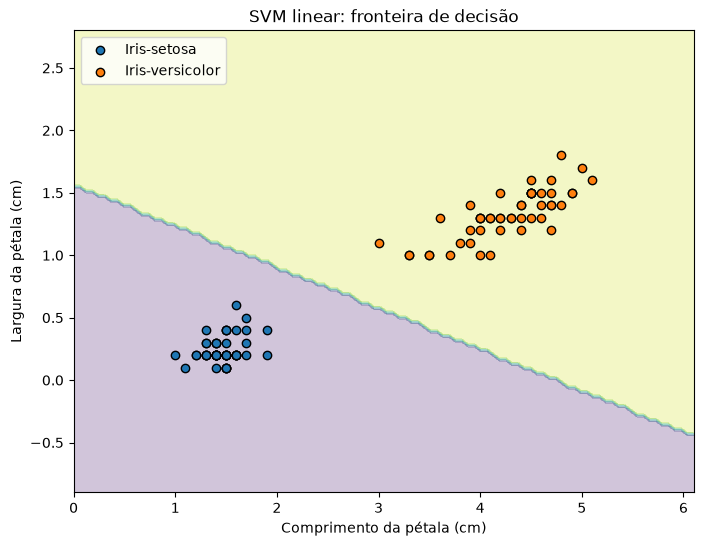

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    model,
    X,
    response_method="predict",
    plot_method="contourf",
    alpha=0.25,
    ax=ax,
)

for species, color in [("Iris-setosa", "tab:blue"), ("Iris-versicolor", "tab:orange")]:
    mask = y == species
    ax.scatter(X.loc[mask, "PetalLengthCm"], X.loc[mask, "PetalWidthCm"], label=species, color=color, edgecolor="k")
    
ax.set_title("SVM linear: fronteira de decisão")
ax.set_xlabel("Comprimento da pétala (cm)")
ax.set_ylabel("Largura da pétala (cm)")
ax.legend(loc="upper left")
plt.show()

## 14. Implementação simplificada do SVM Linear com Gradiente Descendente (*From Scratch*)

Nesta seção, será utilizado o **Gradiente Descendente** para minimizar iterativamente a função objetivo do SVM Linear. Como a perda hinge não é diferenciável em todos os pontos, a implementação utiliza o subgradiente em atualizações de lote completo (*full-batch*).

A implementação seguinte otimiza diretamente a função objetivo de margem flexível

$$\Large J(\mathbf{w},b)=\frac{1}{2}\|\mathbf{w}\|^2+C\sum_i\max(0,1-y_i(\mathbf{w}^{T}\mathbf{x}_i+b))$$

> **Interpretação:** A implementação otimiza a mesma combinação de margem e perda hinge usando Gradiente Descendente com subgradiente.


Utiliza subgradiente e atualização em lotes completos (*full-batch*). Ela é didática, não substitui os solvers convexos e otimizados de bibliotecas especializadas.

Para simplificar a regra de atualização, os rótulos são convertidos para $\{-1,+1\}$. O intercepto não recebe a penalização $\frac12\|\mathbf{w}\|^2$, uma convenção comum.

Importa as bibliotecas necessárias para a implementação manual.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Define o classificador SVM linear usando Gradiente Descendente.

In [8]:
class LinearSVMFromScratch:
    def __init__(self, learning_rate=0.01, n_epochs=2000, C=1.0):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.C = C
        self.w = None
        self.b = None
        self.classes_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        classes = np.unique(y)
        if classes.size != 2:
            raise ValueError("O SVM precisa receber exatamente duas classes.")
        self.classes_ = classes
        y = np.where(y == classes[1], 1.0, -1.0)

        self.w = np.zeros(X.shape[1])
        self.b = 0.0

        for _ in range(self.n_epochs):
            margins = y * (X @ self.w + self.b)
            active = margins < 1

            grad_w = self.w - self.C * (X[active].T @ y[active])
            grad_b = -self.C * y[active].sum()
            self.w = self.w - self.learning_rate * grad_w
            self.b = self.b - self.learning_rate * grad_b
        return self

    def decision_function(self, X):
        if self.w is None or self.b is None:
            raise RuntimeError("O modelo precisa ser ajustado antes da predição.")
        return np.asarray(X) @ self.w + self.b

    def predict(self, X):
        classes = self.classes_
        if classes is None:
            raise RuntimeError("O modelo precisa ser ajustado antes da predição.")
        binary_predictions = np.where(self.decision_function(X) >= 0, 1, -1)
        return np.where(binary_predictions == 1, classes[1], classes[0])

Carrega os dados, prepara os rótulos e treina o SVM manual.

In [9]:
data_path = Path("../data/iris.csv")
df = pd.read_csv(data_path, usecols=["PetalLengthCm", "PetalWidthCm", "Species"])
df = df[df["Species"].isin(["Iris-setosa", "Iris-versicolor"])]

feature_columns = ["PetalLengthCm", "PetalWidthCm"]
X = df[feature_columns]
y = df["Species"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_scratch = LinearSVMFromScratch(learning_rate=0.001, n_epochs=3000, C=1.0)
svm_scratch.fit(X_train_scaled, y_train)
y_pred_scratch = svm_scratch.predict(X_test_scaled)

print(f"Acurácia from scratch: {accuracy_score(y_test, y_pred_scratch):.3f}")
print("Pesos:", svm_scratch.w)
print("Intercepto:", svm_scratch.b)

Acurácia from scratch: 1.000
Pesos: [0.72515529 1.14137925]
Intercepto: 0.2580000000000002


Plota os dados de treino e a linha aprendida pelo SVM.

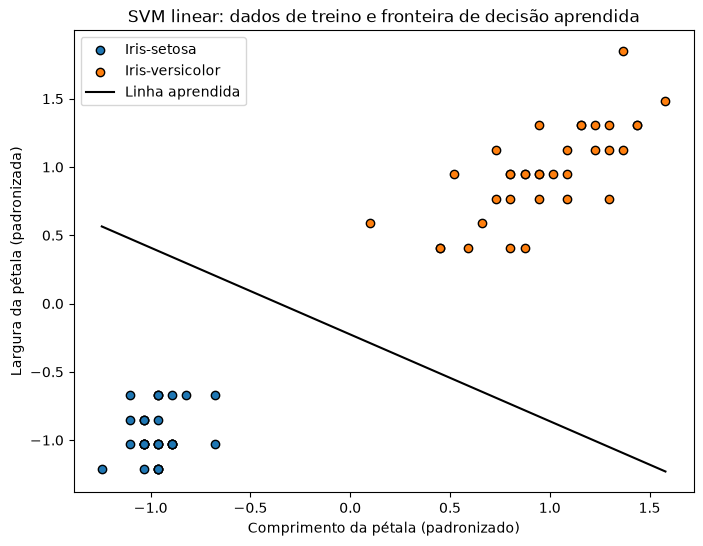

In [10]:
w = svm_scratch.w
b = svm_scratch.b
if w is None or b is None:
    raise RuntimeError("O modelo precisa ser ajustado antes do gráfico.")

x_line = np.linspace(X_train_scaled[:, 0].min(), X_train_scaled[:, 0].max(), 100)
y_line = -(w[0] * x_line + b) / w[1]

fig, ax = plt.subplots(figsize=(8, 6))
for species, color in [("Iris-setosa", "tab:blue"), ("Iris-versicolor", "tab:orange")]:
    mask = y_train == species
    ax.scatter(X_train_scaled[mask, 0], X_train_scaled[mask, 1], label=species, color=color, edgecolor="k")

ax.plot(x_line, y_line, color="black", label="Linha aprendida")
ax.set_title("SVM linear: dados de treino e fronteira de decisão aprendida")
ax.set_xlabel("Comprimento da pétala (padronizado)")
ax.set_ylabel("Largura da pétala (padronizada)")
ax.legend()
plt.show()

### 14.1. O que a implementação revela

A condição `margins < 1` identifica os exemplos que ainda contribuem para a perda hinge. O gradiente desses exemplos puxa o hiperplano para corrigir a violação, enquanto o termo `self.w` implementa a regularização que busca uma margem larga.

A implementação não calcula explicitamente os multiplicadores $\alpha_i$ nem resolve o dual. Mesmo assim, ela evidencia a mesma competição entre **margem** e **violações** que aparece na formulação primal.

## 15. Vantagens e limitações

**Vantagens**

- a maximização da margem favorece boa generalização em muitos problemas;
- kernels permitem fronteiras não lineares sem construir explicitamente todas as features transformadas;
- a formulação convexa evita o problema de mínimos locais típico de objetivos não convexos;
- funciona bem em espaços de alta dimensão, especialmente quando o número de features não é muito maior que o número de amostras.

**Limitações**

- exige escalonamento e escolha cuidadosa de hiperparâmetros;
- treinamento com kernel pode ser lento e consumir muita memória em bases grandes;
- a saída de decisão não é uma probabilidade calibrada;
- outliers podem deslocar a fronteira, sobretudo com $C$ alto;
- a interpretação dos pesos é direta no kernel linear, mas menos simples em kernels não lineares.

## 16. SVM no fluxo de Machine Learning

1. Definir o tipo de erro e a classe positiva relevantes para o problema.
2. Separar treino, validação e teste, preservando a proporção das classes quando necessário.
3. Tratar valores ausentes, codificar variáveis categéricas e escalonar dentro de uma `Pipeline`.
4. Escolher `kernel`, `C` e, quando aplicável, `gamma` por validação cruzada.
5. Treinar o modelo e inspecionar a quantidade de vetores de suporte.
6. Avaliar com métricas coerentes com o custo dos erros.
7. Se probabilidades forem necessárias, calibrar o classificador e validar a calibração.
8. Monitorar mudanças na distribuição dos dados após a implantação.

## 17. Conclusão

O SVM resolve um problema geométrico preciso: encontrar uma fronteira que maximize a margem entre classes. A derivação mostra a cadeia completa:

1. distância entre hiperplanos $\Rightarrow$ maximizar margem;
2. maximizar margem $\Rightarrow$ minimizar $\frac12\|\mathbf{w}\|^2$;
3. dados imperfeitos $\Rightarrow$ variáveis de folga e perda hinge;
4. Lagrangiana e KKT $\Rightarrow$ vetores de suporte e formulação dual;
5. produtos internos no dual $\Rightarrow$ kernel trick e fronteiras não lineares.

A ideia mais importante é que o SVM não busca simplesmente separar o treinamento: ele busca uma separação com margem, controlando explicitamente o compromisso entre complexidade da fronteira e violações por meio de $C$.